# Abstention, selection and the Blue Wall: 2016 and 2024

**ECON 438, Project 1 | Executable research notebook**

**RQ1:** What latent candidate preferences do we predict among retained matched nonvoters, and what do reported prior votes suggest about abstention versus defection?

**RQ2:** Under explicit participation and partisan-allocation assumptions, how many additional participants would overturn Trump's margins in Michigan, Wisconsin and Pennsylvania?

**Headline scenario:** Republican versus non-Republican is the estimated outcome. For the electoral counterfactual only, all predicted non-Republican preferences are allocated to Democrats. This is an optimistic Democratic allocation, not observed Democratic support. Sensitivity varies that allocation.

This notebook freshly estimates **2016 and 2024 separately**. It does not import the earlier reported coefficient estimates. The 2020 extract is available but is not another fitted election in this design. Run all cells in order; tables, figures and an execution manifest are written to `results/`. Numerical routines are in `code/selection_analysis.py`; output routines are in `code/analysis_outputs.py`.


In [1]:
from pathlib import Path
import sys, os
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/prepared/ces_covi_2016_2020_2024.csv.gz').exists())
sys.path.insert(0, str(ROOT/'code'))
from selection_analysis import *
from analysis_outputs import *
TABLES = ROOT/'results/tables'
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda z: f'{z:.4f}')
checks = numerical_checks()
print('Project root:', ROOT)
print('CDF check:', checks)


Project root: /Users/apple/Desktop/ECONO II /Data/Project/P1
CDF check: {'bivariate_cdf_max_absolute_error': 1.8318679906315083e-14, 'reference': 'independent 1D conditional-normal quadrature', 'test_points': 55}


## 1. Data, sample and variables

One observation is a respondent-election. CES turnout is validated against a voter file; candidate choice is self-reported. We retain the existing complete-case `sample_candidate` sample: matched adult citizens in the 50 states, post-wave participation, positive adult post weights, complete controls, and usable reported choice if a validated voter. Nonvoter choice remains missing. Dropping voters with unknown choice is an additional selection restriction, which this model does not separately correct.

- **Selection:** $S_i=1$ for a validated voter, $S_i=0$ for a matched respondent without a recorded vote. Unmatched respondents are excluded, not recoded as nonvoters.
- **Outcome:** $Y_i=1$ Republican; $Y_i=0$ any other reported candidate. Observed only if $S_i=1$.
- **$X_i$:** intercept, age centered at 50 and divided by 10, category indicators for education, income, party identification, ideology, gender and race/ethnicity. References: no HS diploma, income below $30k, strong Democrat, very liberal, male/man and White.
- **$Z_i$:** $X_i$ plus COVI in the joint model. Higher COVI means more costly voting.
- Adult post-wave survey weights are normalized to mean one within each retained sample. These are pseudo-likelihood weights, not frequency counts. Standard errors use weighted observation scores summed by state.

Neither weights nor selection modelling automatically generalize the estimates beyond this restricted matched population. Validation sources/status coverage differ across elections; the 2024 matched records are active registrants.


In [2]:
data, sample_counts, state_counts = load_inputs(ROOT)
display(sample_counts)
display(state_counts[state_counts.state_postal.isin(['MI','WI','PA'])])


,year,original_n,candidate_n,voter_n,nonvoter_n,weighted_sample_turnout,matched_raw_n,unmatched_raw_n,choice_missing_voters_raw_n
0,2016,64600,32453,26914,5539,0.8006,45117,19483,4585
1,2024,60000,31484,29299,2185,0.9485,39800,20200,3507


,year,state_postal,candidate_n,voter_n,nonvoter_n,nonvoter_kish_n
21,2016,MI,1169,964,205,79.5749
37,2016,PA,1900,1608,292,154.1141
47,2016,WI,757,639,118,59.1206
71,2024,MI,1126,1039,87,13.4122
87,2024,PA,1738,1665,73,7.8101
97,2024,WI,736,709,27,6.3682


## 2. Lecture 10 notation: selection before the outcome

The attached *Lecture 10: Limited Dependent Variable Models, Part 8* writes

$$S_i^*=Z_i\gamma+v_i,\qquad S_i=1(S_i^*>0),$$
$$Y_i=X_i\beta+u_i,\qquad Y_i\text{ observed only if }S_i=1.$$

For a continuous normal outcome it derives

$$\lambda(Z_i\gamma)=\frac{\phi(Z_i\gamma)}{\Phi(Z_i\gamma)},\qquad
E(Y_i\mid X_i,Z_i,S_i=1)=X_i\beta+\delta\lambda(Z_i\gamma),\quad\delta=\rho\sigma_u.$$

We reproduce its first-stage probit and generated inverse Mills ratio, then show a **two-step linear-probability teaching diagnostic**. Its second-stage variance uses stacked estimating equations, including first-stage uncertainty. Since our $Y$ is binary, the lecture's continuous-normal second stage is not a correctly specified binary likelihood; its unbounded fitted values are not used for electoral counterfactuals. Adding an inverse Mills ratio to a second probit would not in general be the exact binary correction either.

The main model retains the lecture's $S,Z,\gamma,v$ and $Y,X,\beta,u,\rho$ notation but replaces its continuous outcome by a latent binary preference:

$$Y_i^*=X_i\beta+u_i,\qquad Y_i=1(Y_i^*>0),$$
$$\begin{pmatrix}u_i\\v_i\end{pmatrix}\mid X_i,Z_i\sim N\left[\begin{pmatrix}0\\0\end{pmatrix},\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}\right].$$

Both latent variances are normalized to one. $\rho=\tanh(\alpha)$ is estimated through unrestricted $\alpha$; $\rho=0$ nests independence.

**Identification:** $X\subset Z$ with COVI excluded from preference. COVI must affect turnout without directly affecting preference conditional on $X$; this is an assumption, not a result. Within a single election, COVI is constant by state, so full state indicators would absorb it. Therefore the main joint model omits full state effects; a separate state-FE baseline, a no-state baseline, and a region-control robustness fit expose this tradeoff.


## 3. Binary sample-selection likelihood and correct prediction target

Write $a_i=Z_i\gamma$, $b_i=X_i\beta$ and let $\Phi_2$ denote the bivariate standard-normal CDF. The three observed-data likelihood contributions are

$$L_i=\begin{cases}
\Phi(-a_i),&S_i=0,\\
\Phi_2(a_i,b_i;\rho),&S_i=1,Y_i=1,\\
\Phi_2(a_i,-b_i;-\rho),&S_i=1,Y_i=0.
\end{cases}$$

We maximize $\sum_i w_i\log L_i$ and use the **nonselection-conditional** preference probability

$$p_{Ri}^{NV}=P(Y_i=1\mid X_i,Z_i,S_i=0)
=\frac{\Phi_2(-a_i,b_i;-\rho)}{\Phi(-a_i)}.$$

The marginal $\Phi(b_i)$ is a different estimand. Under $\rho=0$ they coincide. With positive $\rho$, conditioning on nonvoting lowers Republican probability at the same covariates.

Three starting correlations (-0.6, 0, 0.6), likelihood values, scores and Hessian eigenvalues are saved. Numerical convergence does not prove a global maximum, valid exclusion or correct normality. A deterministic Owen's T implementation avoids random-integration noise and is checked against independent one-dimensional quadrature.

Methods reference: [Stata's binary sample-selection likelihood](https://blog.stata.com/2015/10/22/probit-model-with-sample-selection-by-mlexp/). The lecture PDF is a local teaching reference; it is not redistributed in Git.


In [3]:
# Visible notation-to-variable mapping for each separately fitted election.
year = 2016
example = data[data.year.eq(year)].reset_index(drop=True)
S = example.turnout_matched.to_numpy()
Y = example.republican_any.to_numpy()    # Missing for S=0; never imputed before fitting.
X = design(example)
Z = X.assign(COVI=example.covi_final.to_numpy())
assert np.isnan(Y[S == 0]).all()
print('X columns:', list(X.columns))
print('Z adds:', list(set(Z.columns)-set(X.columns)))


X columns: ['constant', 'age_10', 'education_2', 'education_3', 'education_4', 'education_5', 'education_6', 'income_group_2', 'income_group_3', 'income_group_4', 'income_group_5', 'pid7_2', 'pid7_3', 'pid7_4', 'pid7_5', 'pid7_6', 'pid7_7', 'ideology5_2', 'ideology5_3', 'ideology5_4', 'ideology5_5', 'gender_group_2', 'race_h_2', 'race_h_3', 'race_h_4', 'race_h_5', 'race_h_6', 'race_h_7', 'race_h_8']
Z adds: ['COVI']


## 4. Fit the models and the lecture's two steps

For each election we fit: turnout probit with state effects; turnout probit with COVI; voter-choice probit with state effects; voter-choice probit without state effects; and joint binary selection with COVI. Separate turnout and choice probits do not themselves correct unobserved selection.

The reported two-step diagnostic estimates $\widehat\gamma$, constructs $\widehat\lambda_i=\phi(Z_i\widehat\gamma)/\Phi(Z_i\widehat\gamma)$, then regresses selected $Y$ on $X$ and $\widehat\lambda$. It is included to connect the lecture to the main model, not to substitute a continuous-outcome estimator for a binary likelihood.


In [4]:
fits_by_year = {}
two_step_rows = []
for year in [2016, 2024]:
    fits_by_year[year], two_step = run_election(data, year, TABLES)
    two_step_rows.append(two_step)
two_step_table = pd.DataFrame(two_step_rows)
save(two_step_table, TABLES/'lecture_two_step_diagnostic.csv')
display(two_step_table)


2016: fitting turnout and baseline choice...


2016: joint selection likelihood, three starting correlations...


2016: rho=0.3461


2024: fitting turnout and baseline choice...


2024: joint selection likelihood, three starting correlations...


2024: rho=0.8259


,delta,delta_cluster_se,delta_p,nonvoter_linear_mean,nonvoter_prediction_min,nonvoter_prediction_max,nonvoter_outside_0_1_fraction,imr_r2_on_X,year
0,0.2388,0.1335,0.0799,0.0028,-0.6592,0.6615,0.5254,0.9379,2016
1,0.1288,0.2764,0.6433,0.1715,-0.4321,0.7960,0.4407,0.8984,2024


## 5. Inference, national predictions and cross-election comparisons

For parameter vector $\theta$, let $s_i=w_i\partial\log L_i/\partial\theta$, $H=-\partial\sum_i s_i/\partial\theta'$ and $U_g=\sum_{i\in g}s_i$. The cluster covariance is

$$\widehat V=c H^{-1}\left(\sum_g U_gU_g'\right)H^{-1'},\qquad
c=\frac{G}{G-1}\frac{n-1}{n-k}.$$

We use $t_{G-1}$ reference values (50 state clusters in the main fits), not a conventional likelihood-ratio test on a weighted likelihood. For $\rho$, the Wald test operates on $\alpha=\operatorname{atanh}(\rho)$; intervals are transformed back to $[-1,1]$.

National weighted-mean prediction intervals include parameter and observed nonvoter covariate-mix influence. Cross-year contrasts combine influences by the same state, permitting state-level dependence across years. These are model-based cluster asymptotics, not a substitute for unavailable full survey-design information. Linearized probability intervals may leave [0,1] and are not silently truncated.

**State targets:** small state samples, especially 2024, do not support precise population claims. A parameter-only SE conditional on the observed state covariates is exported, but we do not label it a population confidence interval or present deterministic threshold estimates as precise.


In [5]:
preferences, blue_wall, cross_year, diagnostics = preference_results(fits_by_year, TABLES)
display(preferences)
display(cross_year)
display(pd.DataFrame([{k:v for k,v in row.items() if k != 'multistart'} for row in diagnostics if row['model']=='heckprobit_COVI']))


,year,model,p_republican,p_allocated_democratic,cluster_se,r_ci_low,r_ci_high,allocated_d_ci_low,allocated_d_ci_high,nonvoter_n,kish_n,marginal_r_different_target
0,2016,baseline_state_FE,0.4142,0.5858,0.0130,0.3881,0.4403,0.5597,0.6119,5539,2312.1924,NaN
1,2016,probit_no_state_FE,0.4109,0.5891,0.0129,0.3850,0.4368,0.5632,0.6150,5539,2312.1924,NaN
2,2016,heckprobit_COVI,0.3025,0.6975,0.1482,0.0047,0.6002,0.3998,0.9953,5539,2312.1924,0.3843
3,2024,baseline_state_FE,0.4457,0.5543,0.0208,0.4040,0.4874,0.5126,0.5960,2185,308.5772,NaN
4,2024,probit_no_state_FE,0.4425,0.5575,0.0201,0.4021,0.4829,0.5171,0.5979,2185,308.5772,NaN
5,2024,heckprobit_COVI,0.1522,0.8478,0.0633,0.0249,0.2794,0.7206,0.9751,2185,308.5772,0.4165


,model,r_change_2024_minus_2016,cluster_se,ci_low,ci_high,p_value,clusters,assumption
0,baseline_state_FE,0.0315,0.0175,-0.0036,0.0666,0.0774,50,arbitrary dependence within state across years...
1,probit_no_state_FE,0.0316,0.0173,-0.0032,0.0664,0.0743,50,arbitrary dependence within state across years...
2,heckprobit_COVI,-0.1503,0.1655,-0.4828,0.1822,0.3680,50,arbitrary dependence within state across years...


,year,model,weighted_loglik,rho,normalized_max_score,probability_floor_count,q,p,hessian_min_eigenvalue,hessian_condition,rho_se_delta,rho_ci_low,rho_ci_high,rho_wald_p,score_jacobian_asymmetry
0,2016,heckprobit_COVI,-22383.0637,0.3461,0.0000,0,30,29,8.1964,5763.4348,0.4545,-0.5894,0.8851,0.4878,0.0000
1,2024,heckprobit_COVI,-10519.6347,0.8259,0.0000,0,32,31,0.0142,1625571.0744,0.1076,0.4582,0.9522,0.0011,0.0000


In [6]:
# First-stage COVI relevance: a cluster-robust association, not exclusion validity.
coef = pd.concat([pd.read_csv(TABLES/f'coefficients_{year}.csv') for year in [2016,2024]], ignore_index=True)
display(coef[(coef.model=='turnout_COVI') & (coef.term=='COVI')])
# Directly show the lecture's selected/nonselected correction direction.
first = fits_by_year[2016]['turnout_COVI']
a_hat = Z.to_numpy() @ first.theta
lecture_mapping = pd.DataFrame({'S':S, 'Z_gamma_hat':a_hat,
    'lambda_selected':imr(a_hat), 'lambda_nonselected':imr(-a_hat)})
display(lecture_mapping.head())


,model,term,coefficient,cluster_se,t,df,p_value,ci_low,ci_high,year
107,turnout_COVI,COVI,-0.1004,0.0287,-3.4968,49,0.0010,-0.1581,-0.0427,2016
386,turnout_COVI,COVI,-0.0388,0.0251,-1.5498,49,0.1276,-0.0892,0.0115,2024


,S,Z_gamma_hat,lambda_selected,lambda_nonselected
0,1.0000,0.2108,0.6687,0.9368
1,1.0000,0.9255,0.3160,1.4658
2,0.0000,0.7257,0.4002,1.3102
3,1.0000,0.9133,0.3208,1.4562
4,1.0000,0.9273,0.3153,1.4672


## 6. Benchmarks and probability effects

Pre-election preference and post-election hypothetical nonvoter preference are withheld from the regressors and compared on the subsets where each is available. These are noisy, routed survey responses, not true nonvoter ballots. Agreement supports plausibility; disagreement identifies model sensitivity without establishing which answer is correct.

Average partial effects below refer to Republican probability in the state-FE baseline, evaluated over retained nonvoter covariates. Age is a derivative per year; category effects are discrete comparisons with the reference category. They are conditional associations, not causal demographic effects.


In [7]:
benchmarks = benchmark_tables(fits_by_year, TABLES)
effects = partial_effects(fits_by_year, TABLES)
display(benchmarks)
display(effects)


,year,benchmark,available_nonvoter_n,weighted_coverage_among_nonvoters,stated_r_share,baseline_predicted_r_same_subset,heck_predicted_r_same_subset
0,2016,Pre-election stated preference,4436,0.8296,0.3780,0.4084,0.3045
1,2016,Post-election hypothetical nonvoter preference,1884,0.2991,0.4048,0.4364,0.3047
2,2024,Pre-election stated preference,1883,0.9022,0.4560,0.4411,0.1598
3,2024,Post-election hypothetical nonvoter preference,980,0.1838,0.3900,0.3989,0.0967


,year,contrast,r_probability_change,parameter_only_cluster_se,ci_low,ci_high,target
0,2016,Age +1 year (derivative),0.0019,0.0002,0.0015,0.0024,"retained nonvoter covariate distribution, held..."
1,2016,Four-year degree vs no HS,-0.0574,0.0224,-0.1023,-0.0124,"retained nonvoter covariate distribution, held..."
2,2016,Postgraduate vs no HS,-0.0701,0.0225,-0.1153,-0.0249,"retained nonvoter covariate distribution, held..."
3,2016,Female/woman vs male/man,-0.0102,0.0078,-0.0258,0.0054,"retained nonvoter covariate distribution, held..."
4,2016,Black vs White,-0.1408,0.0300,-0.2012,-0.0805,"retained nonvoter covariate distribution, held..."
5,2016,Hispanic vs White,-0.0657,0.0142,-0.0941,-0.0372,"retained nonvoter covariate distribution, held..."
6,2024,Age +1 year (derivative),0.0005,0.0002,0.0000,0.0010,"retained nonvoter covariate distribution, held..."
7,2024,Four-year degree vs no HS,-0.0446,0.0161,-0.0769,-0.0122,"retained nonvoter covariate distribution, held..."
8,2024,Postgraduate vs no HS,-0.0565,0.0186,-0.0939,-0.0190,"retained nonvoter covariate distribution, held..."
9,2024,Female/woman vs male/man,0.0126,0.0068,-0.0010,0.0263,"retained nonvoter covariate distribution, held..."


## 7. Abstention versus defection: descriptive prior-vote transitions

The supplementary extract joins within election on `(year, case_id)` using 2016 `CC16_326` (reported 2012 vote) and 2024 `presvote20post` (stored self-reported 2020 vote). Neither prior candidate choice is voter-file validated; we do not assert that the data are a validated longitudinal panel. This is a transition description within the surviving restricted sample, not a decomposition of the electorate's change. Coverage and unknown prior choices are reported separately; newcomers and reverse flows also matter.

Current abstention uses validated turnout; current candidate choice uses the survey response. Actual other-candidate choices remain separate in this descriptive table so allocation assumptions do not rewrite observed responses. A 2016 Sanders-primary subgroup is exploratory and self-reported. Available information does not identify Gaza or moderation as causes of 2024 abstention.


In [8]:
transitions = transition_tables(data, TABLES)
display(pd.read_csv(TABLES/'prior_vote_coverage.csv'))
display(transitions[(transitions.area=='National') & (transitions.prior_group=='Prior Democrat')])
display(pd.read_csv(TABLES/'sanders_descriptive_transitions.csv'))


,year,area,sample_n,known_prior_vote_n,weighted_known_prior_fraction
0,2016,National,32453,27958,0.8255
1,2016,MI,1169,1027,0.8761
2,2016,WI,757,670,0.8750
3,2016,PA,1900,1567,0.8144
4,2024,National,31484,31481,0.9999
5,2024,MI,1126,1126,1.0000
6,2024,WI,736,736,1.0000
7,2024,PA,1738,1738,1.0000


,year,area,prior_group,current_status,prior_group_n,cell_n,weighted_fraction_within_prior_group,prior_group_kish_n
0,2016,National,Prior Democrat,Democrat,15772,11697,0.7120,6419.2033
1,2016,National,Prior Democrat,Republican,15772,1077,0.0790,6419.2033
2,2016,National,Prior Democrat,Other candidate,15772,811,0.0317,6419.2033
3,2016,National,Prior Democrat,Abstained,15772,2187,0.1772,6419.2033
56,2024,National,Prior Democrat,Democrat,16308,14897,0.9093,5472.1404
57,2024,National,Prior Democrat,Republican,16308,292,0.0390,5472.1404
58,2024,National,Prior Democrat,Other candidate,16308,301,0.0106,5472.1404
59,2024,National,Prior Democrat,Abstained,16308,818,0.0410,5472.1404


,year,group,current_status,group_n,cell_n,weighted_fraction
0,2016,Self-reported Sanders primary voters,Democrat,5386,3705,0.6817
1,2016,Self-reported Sanders primary voters,Republican,5386,436,0.1009
2,2016,Self-reported Sanders primary voters,Other candidate,5386,657,0.0847
3,2016,Self-reported Sanders primary voters,Abstained,5386,588,0.1327


## 8. Battleground arithmetic and the two-party allocation scenario

Let $d_s=V_{Rs}-V_{Ds}>0$ be the official Republican lead, $A_s$ the hypothetical number of additional participants and $q$ the fraction of the predicted non-Republican bloc allocated to Democrats. The remainder vote for other candidates. With existing ballots fixed,

$$\Delta_s=A_s\{q(1-p_{Rs}^{NV})-p_{Rs}^{NV}\}.$$

The expected Democratic net gain overturns the margin if $\Delta_s>d_s$. When the expression in braces is positive, the smallest integer count of additional participants is

$$A_s^{min}=\left\lfloor\frac{d_s}{q(1-p_{Rs}^{NV})-p_{Rs}^{NV}}\right\rfloor+1.$$

The break-even allocation is $q^*=p_R/(1-p_R)$. Headline $q=1$ assigns all non-Republicans to Democrats; sensitivity also uses $q=0.9,0.8,2/3,0.5$. This allocation is not a refitted true Democratic-choice probability. The counterfactual assumes added participants have the modelled retained-nonvoter composition and stable preferences.

We **do not** inflate CES weights into a state nonvoter population. Without external, aligned population counts and justified transportability, these are required-participation thresholds, not evidence that enough such people existed or that full turnout would have flipped a state.

Official margins come from [FEC 2016 returns](https://www.fec.gov/resources/cms-content/documents/federalelections2016.pdf) and [FEC 2024 returns](https://www.fec.gov/documents/5644/2024presgeresults.pdf). Flipping all three states reallocates 46 electoral votes in 2016 and 44 in 2024, holding all other states fixed. The 2016 EC illustration uses standard state allocations before faithless electors.


In [9]:
official_returns = pd.read_csv(ROOT/'data/analysis/official_blue_wall_returns.csv')
thresholds = counterfactuals(blue_wall, official_returns, TABLES)
display(blue_wall[blue_wall.model.isin(['baseline_state_FE','heckprobit_COVI'])])
display(thresholds[(thresholds.q_nonR_to_D==1) & thresholds.model.isin(['baseline_state_FE','heckprobit_COVI'])])
display(pd.read_csv(TABLES/'electoral_college_arithmetic.csv'))


,year,state_postal,model,p_republican,p_allocated_democratic,parameter_only_se,nonvoter_n,kish_n,state_population_ci_available
0,2016,MI,baseline_state_FE,0.4159,0.5841,0.0045,205,79.5749,False
1,2016,WI,baseline_state_FE,0.4064,0.5936,0.0043,118,59.1206,False
2,2016,PA,baseline_state_FE,0.4534,0.5466,0.0026,292,154.1141,False
6,2016,MI,heckprobit_COVI,0.2991,0.7009,0.1488,205,79.5749,False
7,2016,WI,heckprobit_COVI,0.3008,0.6992,0.1677,118,59.1206,False
8,2016,PA,heckprobit_COVI,0.3141,0.6859,0.1675,292,154.1141,False
9,2024,MI,baseline_state_FE,0.5014,0.4986,0.0044,87,13.4122,False
10,2024,WI,baseline_state_FE,0.3892,0.6108,0.0076,27,6.3682,False
11,2024,PA,baseline_state_FE,0.4178,0.5822,0.0088,73,7.8101,False
15,2024,MI,heckprobit_COVI,0.2020,0.7980,0.0702,87,13.4122,False


,year,state_postal,model,q_nonR_to_D,p_republican,net_dem_votes_per_added_participant,rep_margin,minimum_additional_participants,nonvoter_n,kish_n,q_break_even
0,2016,MI,baseline_state_FE,1.0000,0.4159,0.1681,10704,63667.0000,205,79.5749,0.7121
5,2016,WI,baseline_state_FE,1.0000,0.4064,0.1872,22748,121493.0000,118,59.1206,0.6846
10,2016,PA,baseline_state_FE,1.0000,0.4534,0.0931,44292,475572.0000,292,154.1141,0.8296
30,2016,MI,heckprobit_COVI,1.0000,0.2991,0.4018,10704,26644.0000,205,79.5749,0.4268
35,2016,WI,heckprobit_COVI,1.0000,0.3008,0.3983,22748,57107.0000,118,59.1206,0.4303
40,2016,PA,heckprobit_COVI,1.0000,0.3141,0.3719,44292,119100.0000,292,154.1141,0.4578
45,2024,MI,baseline_state_FE,1.0000,0.5014,-0.0029,80103,NaN,87,13.4122,1.0057
50,2024,WI,baseline_state_FE,1.0000,0.3892,0.2217,29397,132627.0000,27,6.3682,0.6371
55,2024,PA,baseline_state_FE,1.0000,0.4178,0.1644,120266,731370.0000,73,7.8101,0.7176
75,2024,MI,heckprobit_COVI,1.0000,0.2020,0.5960,80103,134397.0000,87,13.4122,0.2531


,year,dem_ec_before_faithless,rep_ec_before_faithless,ev_reallocated_if_all_three_flip,dem_ec_if_all_three_flip,rep_ec_if_all_three_flip,note
0,2016,232,306,46,278,260,Standard state allocations before faithless el...
1,2024,226,312,44,270,268,Hold all other states fixed.


## 9. Robustness: identification and the matching population

Refit joint selection after (i) removing COVI, leaving functional-form identification only, (ii) excluding Utah, whose private-registration rules affect matching, (iii) restricting 2016 to active records to approach the 2024 status coverage, and (iv) adding Census-region controls to both equations while retaining COVI variation within regions. These alter assumptions or the represented sample; they are not all estimates of an identical target population.

Each robustness fit uses two starting correlations. Differences and interval width are substantive findings; we do not choose the fit that best supports a political narrative. No specification with single-year full state indicators can separately identify COVI.


In [10]:
robustness_results = robustness(data, TABLES)
display(robustness_results)


2016: robustness no_exclusion...


2016: robustness exclude_Utah...


2016: robustness active_file_only...


2016: robustness region_controls...


2024: robustness no_exclusion...


2024: robustness exclude_Utah...


2024: robustness region_controls...


,year,variant,n,nonvoter_n,p_republican,r_ci_low,r_ci_high,rho,rho_ci_low,rho_ci_high,rho_p,max_score
0,2016,no_exclusion,32453,5539,0.3975,0.3712,0.4238,0.0436,-0.0221,0.1089,0.1886,0.0000
1,2016,exclude_Utah,32185,5498,0.3474,0.2415,0.4534,0.2121,-0.1416,0.5177,0.2322,0.0000
2,2016,active_file_only,29373,2535,0.3478,0.2768,0.4189,0.1081,-0.0811,0.2898,0.2561,0.0000
3,2016,region_controls,32453,5539,0.3967,0.3577,0.4357,0.0565,-0.0681,0.1794,0.3666,0.0000
4,2024,no_exclusion,31484,2185,0.2225,0.0386,0.4064,0.6794,0.0717,0.9192,0.0325,0.0000
5,2024,exclude_Utah,31352,2179,0.1524,0.0244,0.2804,0.8257,0.4527,0.9528,0.0012,0.0000
6,2024,region_controls,31484,2185,0.1974,0.0288,0.3660,0.7485,0.1990,0.9399,0.0144,0.0000


## 10. Figures and reproducibility record

The figures show allocation-scenario estimates and threshold sensitivity, not observed Democratic ballots or causal effects. Detailed coefficient tables, diagnostic records, benchmark tables, transitions, and scenario grids are all saved under `results/`.


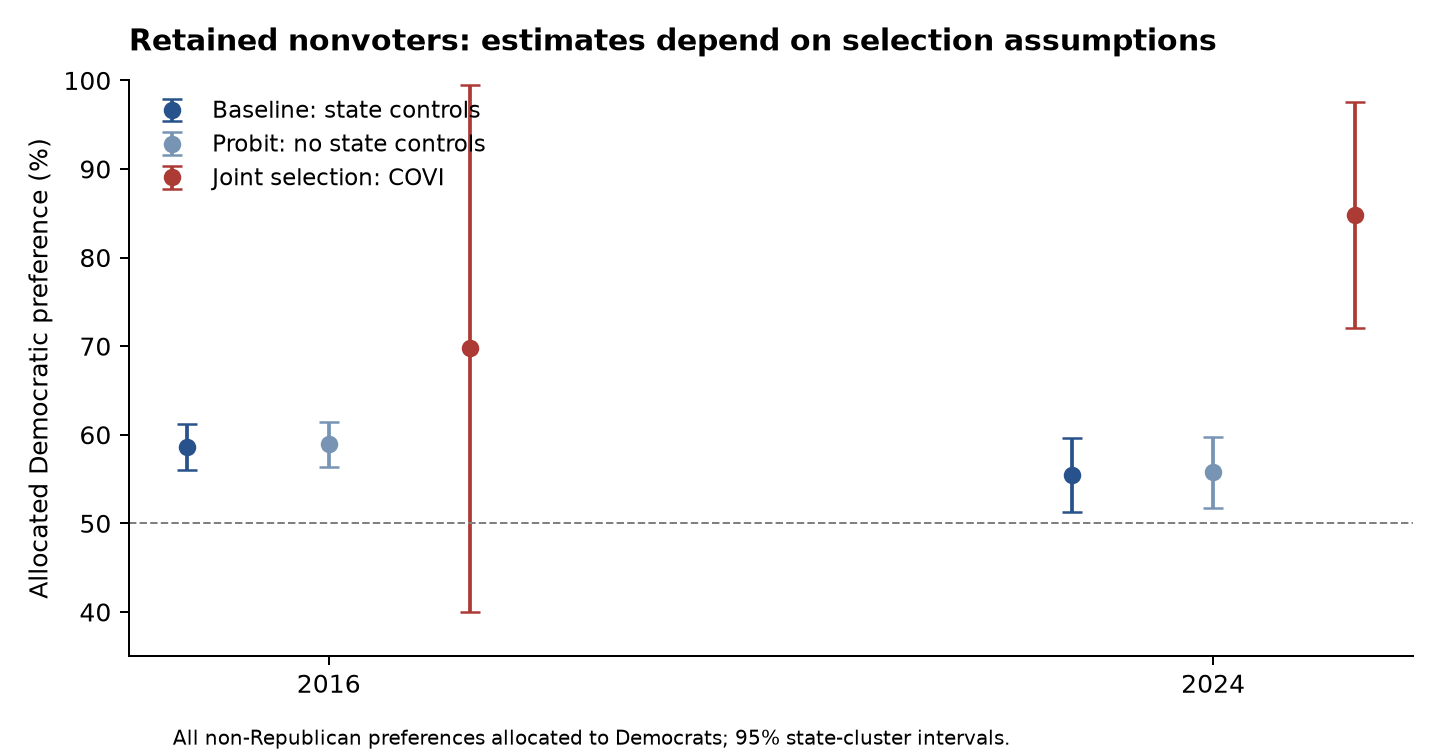

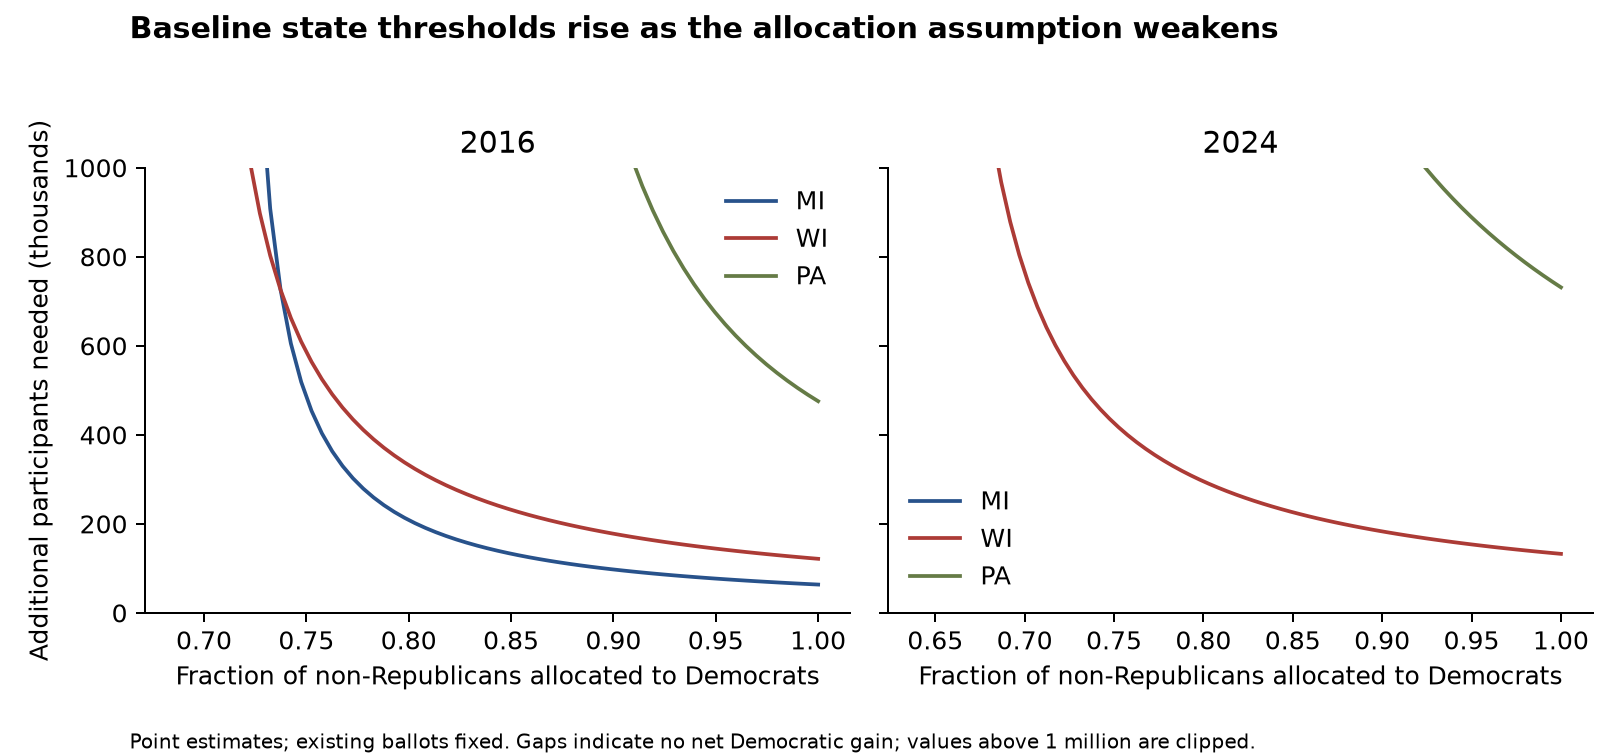

Completed. Tables: 18


In [11]:
make_figures(preferences, blue_wall, thresholds, ROOT)
write_manifest(ROOT, checks)
display(Image(filename=str(ROOT/'results/figures/national_preferences.png')))
display(Image(filename=str(ROOT/'results/figures/state_threshold_sensitivity.png')))
print('Completed. Tables:', len(list(TABLES.glob('*.csv'))))


## Interpretation boundaries

1. **Restricted population:** file matching, active-status coverage, post-wave attrition, complete controls and usable voter choice can select the sample. Turnout selection does not correct all these processes.
2. **Exclusion and normality:** cross-state COVI can proxy politics; strong predictive relevance would still not prove exclusion validity. Large $\rho$ and unstable adjustments warrant caution.
3. **Two-party allocation:** $1-p_R$ is non-Republican; assigning it to Democrats is explicit counterfactual pooling. Third-party handling materially changes net gains.
4. **State uncertainty:** 2024 matched nonvoter samples can have very small weighted effective sizes. State thresholds are point scenarios, not causal or precise population estimates.
5. **Stable behaviour:** new participation could change campaigns, persuasion and preferences. Holding all existing votes fixed excludes those responses.
6. **Historical explanation:** current latent preferences and prior self-reports cannot establish that abstention, Sanders support, Gaza or candidate moderation caused either victory. The project evaluates compatible scenarios and competing descriptive patterns.

**Course-project claim:** estimate selection-sensitive preferences and transparent Electoral College thresholds. A causal explanation of either election requires additional identification and population evidence.
